import

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from libpysal.weights import KNN
from esda.moran import Moran
from esda.moran import Moran_Local


dataset
UIC Injections

                              time   latitude   longitude   mag
0 2010-01-01 00:10:43.792000+00:00  61.032200 -151.658700  1.60
1 2010-01-01 00:16:49.190000+00:00  48.203167 -121.676833  2.20
2 2010-01-01 00:16:54.480000+00:00  36.032000 -117.782167  1.10
3 2010-01-01 00:29:29.585000+00:00  60.147000 -141.055000  1.40
4 2010-01-01 00:30:16.720000+00:00  33.474667 -116.426833  0.75
(2119693, 4)
['time', 'latitude', 'longitude', 'mag']
            injection_volume  active_wells
date                                      
2011-01-01      1.635255e+08         10386
2011-02-01      1.448641e+08         10386
2011-03-01      1.687305e+08         10386
2011-04-01      1.622064e+08         10386
2011-05-01      1.675129e+08         10386
            earthquake_frequency  max_magnitude  mean_magnitude
date                                                           
2010-01-01                     9            3.8        3.088889
2010-02-01                    11            4.1        2.890909
2010-

C:\Users\Денис\AppData\Local\Temp\ipykernel_24008\4185224753.py:95: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period('M')


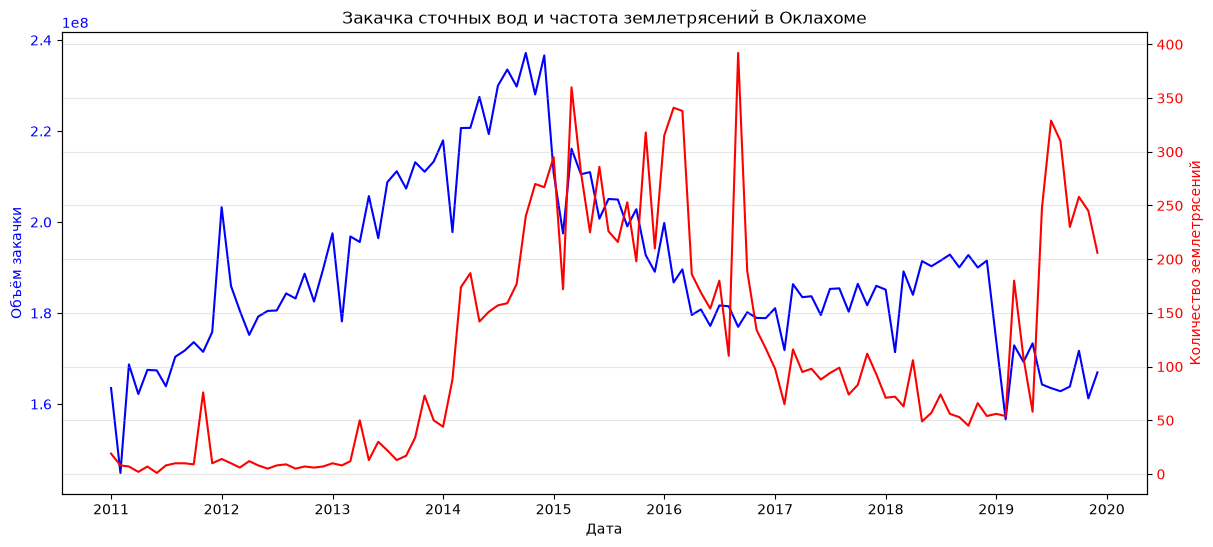

In [35]:
# 1. Загрузка датасетов

file_path = 'data/uic_injection_volumes_2011_2019.csv'
df = pd.read_csv(file_path)

earthquakes = pd.read_csv(
    'data/earthquakes_2010_2026.csv',
    usecols=['time', 'latitude', 'longitude', 'mag'],
    parse_dates=['time']
)

print(earthquakes.head())
print(earthquakes.shape)
print(earthquakes.columns.tolist())

# 2. Подготовка данных о закачке

months = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

volume_columns = [f'{month} Vol' for month in months]

# Оставляем только корректные координаты Оклахомы
injection_source = df.dropna(
    subset=['API', 'Year', 'LAT', 'LON']
).copy()

injection_source = injection_source[
    injection_source['LAT'].between(33, 37) &
    injection_source['LON'].between(-103, -94)
]

volume_long = injection_source.melt(
    id_vars=['API', 'Year', 'County', 'LAT', 'LON'],
    value_vars=volume_columns,
    var_name='month',
    value_name='injection_volume'
)

volume_long['month'] = volume_long['month'].str.replace(
    ' Vol',
    '',
    regex=False
)

month_numbers = {
    month: number
    for number, month in enumerate(months, start=1)
}

volume_long['month_number'] = (
    volume_long['month'].map(month_numbers)
)

volume_long['date'] = pd.to_datetime(
    dict(
        year=volume_long['Year'],
        month=volume_long['month_number'],
        day=1
    )
)

monthly_injection = (
    volume_long
    .groupby('date')
    .agg(
        injection_volume=('injection_volume', 'sum'),
        active_wells=('API', 'nunique')
    )
    .sort_index()
)

print(monthly_injection.head())

# injection_volume — месячный объём закачки;
# active_wells — количество скважин;
# date — месяц.

# 3. Подготовка землетрясений Оклахомы

earthquakes_ok = earthquakes.dropna(
    subset=['time', 'latitude', 'longitude', 'mag']
).copy()

# Приближённые границы Оклахомы
earthquakes_ok = earthquakes_ok[
    earthquakes_ok['latitude'].between(33, 37) &
    earthquakes_ok['longitude'].between(-103, -94)
]

earthquakes_ok['date'] = (
    earthquakes_ok['time']
    .dt.to_period('M')
    .dt.to_timestamp()
)

monthly_earthquakes = (
    earthquakes_ok
    .groupby('date')
    .agg(
        earthquake_frequency=('mag', 'size'),
        max_magnitude=('mag', 'max'),
        mean_magnitude=('mag', 'mean')
    )
    .sort_index()
)

print(monthly_earthquakes.head())
print(monthly_earthquakes.tail())

# earthquake_frequency — количество землетрясений за месяц;
# max_magnitude — самое сильное землетрясение;
# mean_magnitude — средняя магнитуда.

# 4. Объединение двух датасетов

analysis_data = monthly_injection.join(
    monthly_earthquakes,
    how='left'
)

analysis_data['earthquake_frequency'] = (
    analysis_data['earthquake_frequency']
    .fillna(0)
)

analysis_data['max_magnitude'] = (
    analysis_data['max_magnitude']
    .fillna(0)
)

analysis_data['mean_magnitude'] = (
    analysis_data['mean_magnitude']
    .fillna(0)
)

print(analysis_data.head())
print(analysis_data.columns)

# 5. График закачки и землетрясений

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    analysis_data.index,
    analysis_data['injection_volume'],
    color='blue',
    label='Объём закачки'
)

ax1.set_xlabel('Дата')
ax1.set_ylabel('Объём закачки', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()

ax2.plot(
    analysis_data.index,
    analysis_data['earthquake_frequency'],
    color='red',
    label='Количество землетрясений'
)

ax2.set_ylabel(
    'Количество землетрясений',
    color='red'
)
ax2.tick_params(axis='y', labelcolor='red')

plt.title(
    'Закачка сточных вод и частота землетрясений в Оклахоме'
)
plt.grid(alpha=0.3)
plt.show()

## Числовое описание данных

В этом разделе приведены основные размеры, период и диапазоны значений после фильтрации данных по области анализа.

In [36]:
injection_columns = ['API', 'Year', 'LAT', 'LON']
earthquake_columns = ['time', 'latitude', 'longitude', 'mag']

earthquakes_analysis = earthquakes_ok[
    (earthquakes_ok['date'] >= analysis_data.index.min()) &
    (earthquakes_ok['date'] <= analysis_data.index.max())
].copy()

summary = pd.DataFrame({
    'Показатель': [
        'Количество скважин',
        'Количество землетрясений',
        'Начало общего периода',
        'Конец общего периода',
        'Минимальный месячный объём закачки',
        'Средний месячный объём закачки',
        'Максимальный месячный объём закачки',
        'Минимальная магнитуда',
        'Средняя магнитуда',
        'Максимальная магнитуда'
    ],
    'Значение': [
        injection_source['API'].nunique(),
        len(earthquakes_analysis),
        analysis_data.index.min().date(),
        analysis_data.index.max().date(),
        monthly_injection['injection_volume'].min(),
        monthly_injection['injection_volume'].mean(),
        monthly_injection['injection_volume'].max(),
        earthquakes_analysis['mag'].min(),
        earthquakes_analysis['mag'].mean(),
        earthquakes_analysis['mag'].max()
    ]
})

print('Основные характеристики:')
print(summary.to_string(index=False))

missing_summary = pd.DataFrame({
    'Источник': ['Закачка', 'Землетрясения'],
    'Пропуски до очистки': [
        df[injection_columns].isna().sum().sum(),
        earthquakes[earthquake_columns].isna().sum().sum()
    ],
    'Пропуски после очистки': [
        injection_source[injection_columns].isna().sum().sum(),
        earthquakes_ok[earthquake_columns].isna().sum().sum()
    ]
})

print('\nПропущенные значения в ключевых столбцах:')
print(missing_summary.to_string(index=False))

Основные характеристики:
                         Показатель          Значение
                 Количество скважин             13362
           Количество землетрясений             12480
              Начало общего периода        2011-01-01
               Конец общего периода        2019-12-01
 Минимальный месячный объём закачки   144864085.90501
     Средний месячный объём закачки  189196752.342687
Максимальный месячный объём закачки  237170422.781188
              Минимальная магнитуда              0.51
                  Средняя магнитуда          2.556583
             Максимальная магнитуда               5.8

Пропущенные значения в ключевых столбцах:
     Источник  Пропуски до очистки  Пропуски после очистки
      Закачка                   18                       0
Землетрясения                    0                       0


Preskúmajte a analyzujte pridelené dáta tak, aby ste dokázali opísať ich obsah, charakteristiky, priestorové a časové vlastnosti, identifikovať zaujímavé vzory a závislosti a na základe vykonanej analýzy vysvetliť, čo sa v dátach deje a aké závery z nich možno vyvodiť.
1. <br>
2. <br>
3. <br>
4. <br>
5. <br>
6. <br>
7. <br>
8. <br>
9. <br>
10. <br>

In [37]:
# 1. Подготовка временного ряда

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

volume_columns = [f'{month} Vol' for month in months]

# Переводим месяцы из отдельных столбцов в строки
# !!!!!!!!!!!!!!!!!! injection_source // df чат говорит что инжекшин 
volume_long = injection_source.melt(
    id_vars=['API', 'Year'],
    value_vars=volume_columns,
    var_name='month',
    value_name='volume'
)

# Название месяца: "Jan Vol" -> "Jan"
volume_long['month'] = volume_long['month'].str.replace(
    ' Vol', '', regex=False
)

# Номер месяца
month_numbers = {month: number for number, month in enumerate(months, start=1)}
volume_long['month_number'] = volume_long['month'].map(month_numbers)

# Создаём дату: первое число каждого месяца
volume_long['date'] = pd.to_datetime(
    dict(
        year=volume_long['Year'],
        month=volume_long['month_number'],
        day=1
    )
)

# Агрегируем данные по всем скважинам
monthly = (
    volume_long
    .groupby('date')
    .agg(
        total_volume=('volume', 'sum'),
        mean_volume=('volume', 'mean'),
        number_of_records=('volume', 'count')
    )
    .sort_index()
)

print(monthly.head())
print(monthly.tail())

            total_volume   mean_volume  number_of_records
date                                                     
2011-01-01  1.635255e+08  15735.706126              10392
2011-02-01  1.448641e+08  13939.962077              10392
2011-03-01  1.687305e+08  16236.574843              10392
2011-04-01  1.622064e+08  15608.772211              10392
2011-05-01  1.675129e+08  16119.409684              10392
            total_volume   mean_volume  number_of_records
date                                                     
2019-08-01   162826582.0  14361.137943              11338
2019-09-01   163845417.0  14450.998148              11338
2019-10-01   171714875.0  15145.076292              11338
2019-11-01   161245913.0  14221.724555              11338
2019-12-01   166963021.0  14725.967631              11338


Используемый период: 2011–2019


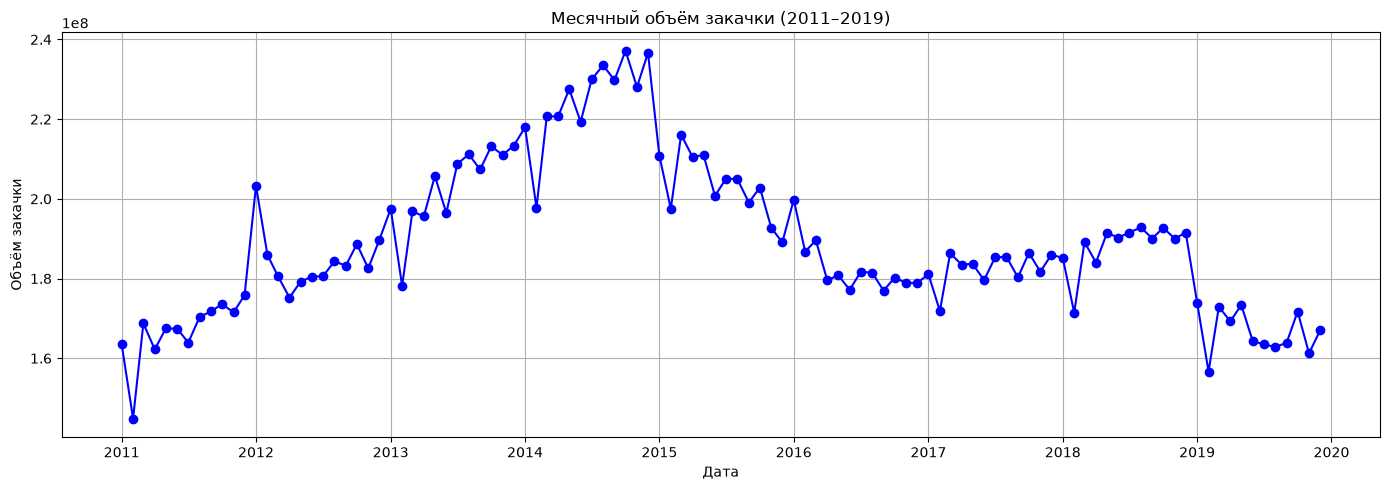

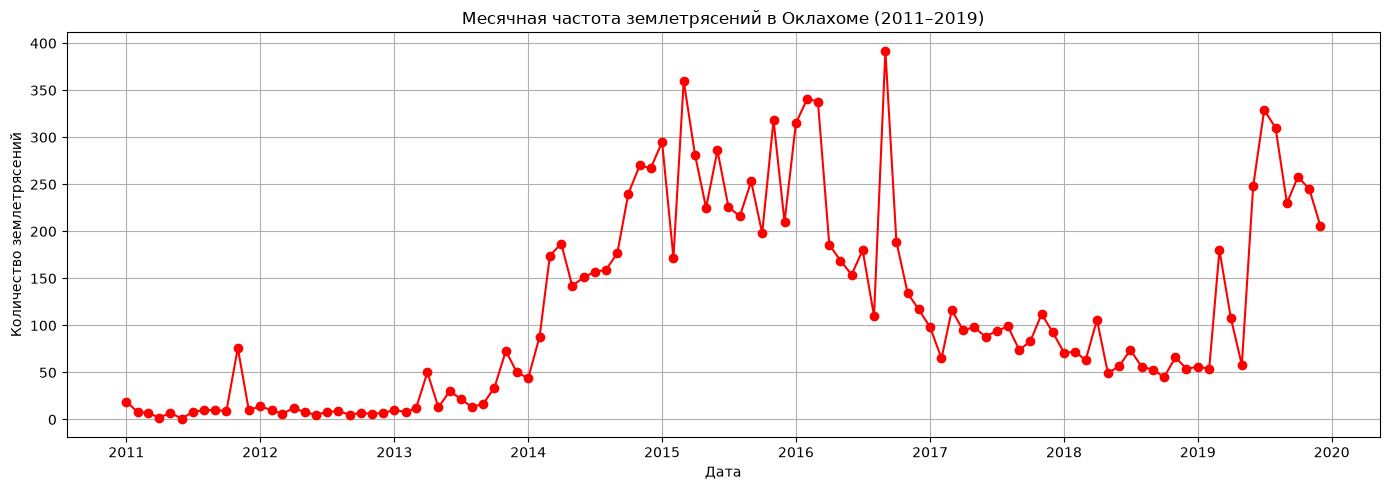

['API', 'Year', 'month', 'volume', 'month_number', 'date']


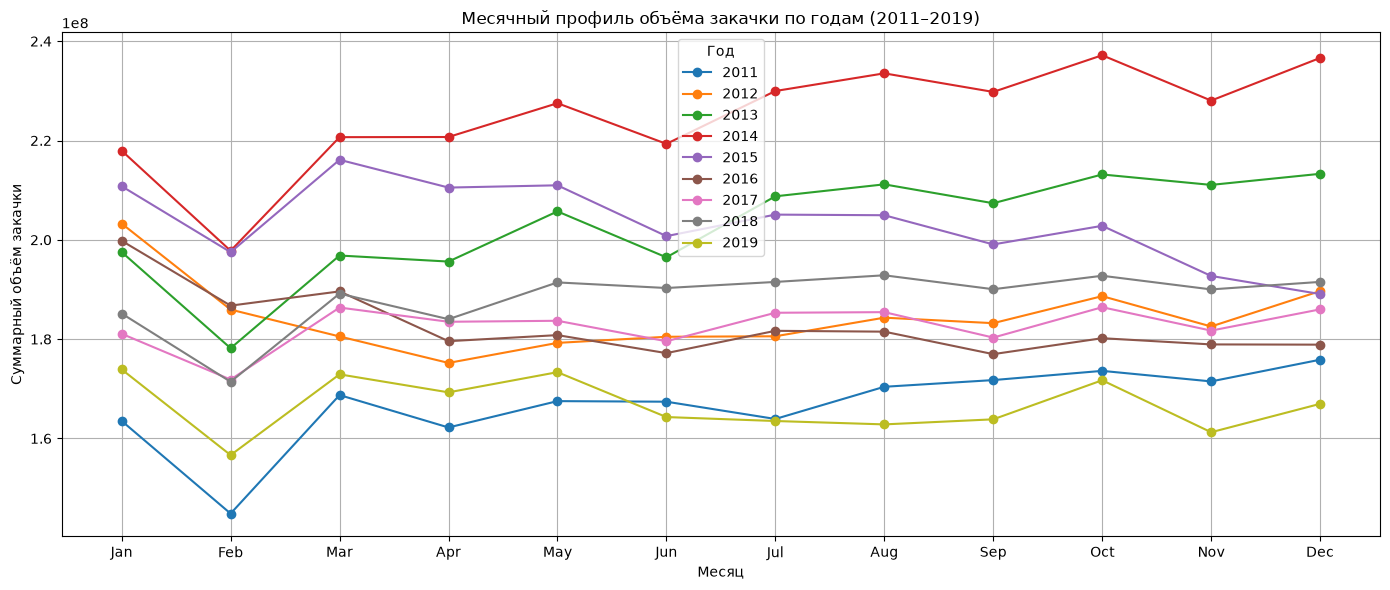

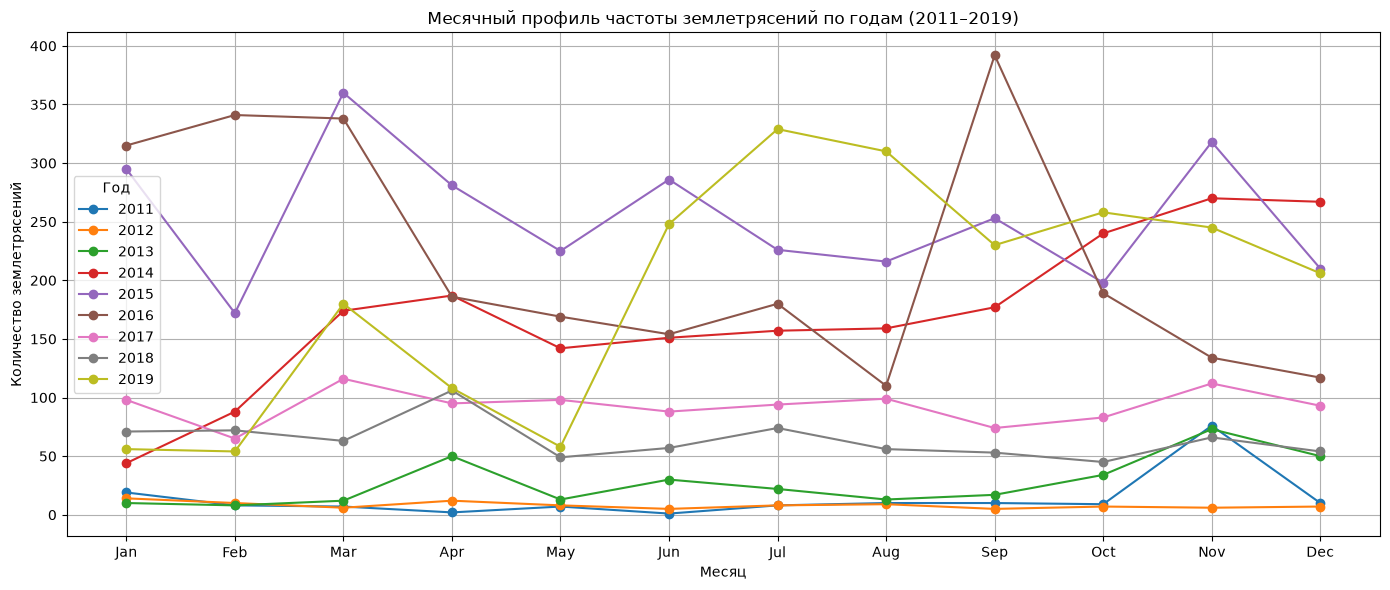

In [38]:
# 2. Тренд и сезонность

# Определяем общий период данных о закачке
start_date = monthly.index.min()
end_date = monthly.index.max()

start_year = start_date.year
end_year = end_date.year

print(
    f'Используемый период: '
    f'{start_year}–{end_year}'
)


# -------------------------------
# 1. Фильтрация землетрясений
# -------------------------------

earthquakes_common = earthquakes_ok[
    (earthquakes_ok['date'] >= start_date) &
    (earthquakes_ok['date'] <= end_date)
].copy()

earthquakes_common['Year'] = (
    earthquakes_common['date'].dt.year
)

earthquakes_common['month'] = (
    earthquakes_common['date'].dt.month_name().str[:3]
)


# -------------------------------
# 2. Тренд объёма закачки
# -------------------------------

plt.figure(figsize=(14, 5))

plt.plot(
    monthly.index,
    monthly['total_volume'],
    marker='o',
    color='blue'
)

plt.title(
    f'Месячный объём закачки ({start_year}–{end_year})'
)
plt.xlabel('Дата')
plt.ylabel('Объём закачки')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 3. Тренд частоты землетрясений
# -------------------------------

monthly_earthquakes_common = (
    earthquakes_common
    .groupby('date')
    .size()
    .reindex(monthly.index, fill_value=0)
)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_earthquakes_common.index,
    monthly_earthquakes_common.values,
    marker='o',
    color='red'
)

plt.title(
    f'Месячная частота землетрясений '
    f'в Оклахоме ({start_year}–{end_year})'
)
plt.xlabel('Дата')
plt.ylabel('Количество землетрясений')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 4. Сезонность закачки
# -------------------------------

print(volume_long.columns.tolist())

volume_long_common = volume_long[
    volume_long['Year'].between(start_year, end_year)
].copy()

seasonal_injection = (
    volume_long_common
    .groupby(['Year', 'month'])['volume']
    .sum()
    .unstack()
    .reindex(columns=months)
)

plt.figure(figsize=(14, 6))

for year in seasonal_injection.index:
    plt.plot(
        months,
        seasonal_injection.loc[year],
        marker='o',
        label=str(year)
    )

plt.title(
    f'Месячный профиль объёма закачки '
    f'по годам ({start_year}–{end_year})'
)
plt.xlabel('Месяц')
plt.ylabel('Суммарный объём закачки')
plt.legend(title='Год')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 5. Сезонность землетрясений
# -------------------------------

seasonal_earthquakes = (
    earthquakes_common
    .groupby(['Year', 'month'])
    .size()
    .unstack()
    .reindex(columns=months)
    .fillna(0)
)

plt.figure(figsize=(14, 6))

for year in seasonal_earthquakes.index:
    plt.plot(
        months,
        seasonal_earthquakes.loc[year],
        marker='o',
        label=str(year)
    )

plt.title(
    f'Месячный профиль частоты землетрясений '
    f'по годам ({start_year}–{end_year})'
)
plt.xlabel('Месяц')
plt.ylabel('Количество землетрясений')
plt.legend(title='Год')
plt.grid(True)
plt.tight_layout()
plt.show()

Ряд объёма закачки:
date
2011-01-01    1.635255e+08
2011-02-01    1.448641e+08
2011-03-01    1.687305e+08
2011-04-01    1.622064e+08
2011-05-01    1.675129e+08
Freq: MS, Name: total_volume, dtype: float64
Период: 2011-01-01 — 2019-12-01
Ряд частоты землетрясений:
date
2011-01-01    19.0
2011-02-01     8.0
2011-03-01     7.0
2011-04-01     2.0
2011-05-01     7.0
Freq: MS, dtype: float64


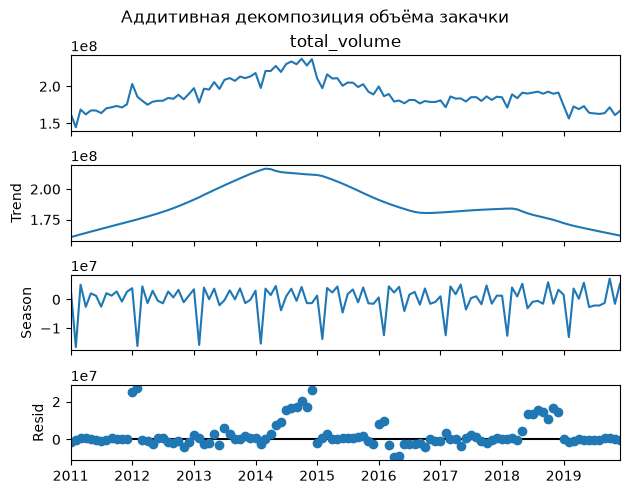

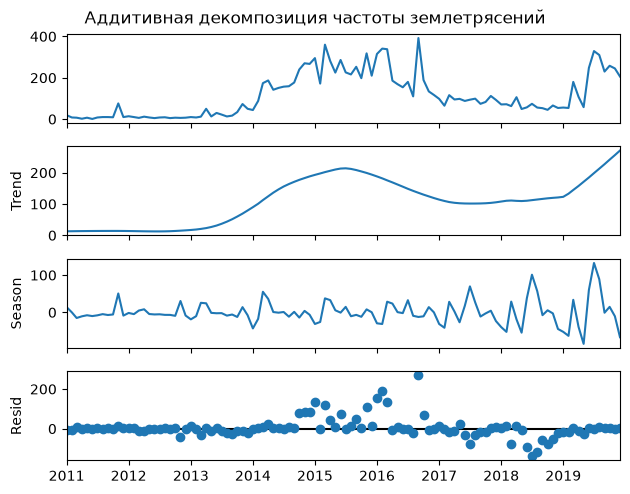

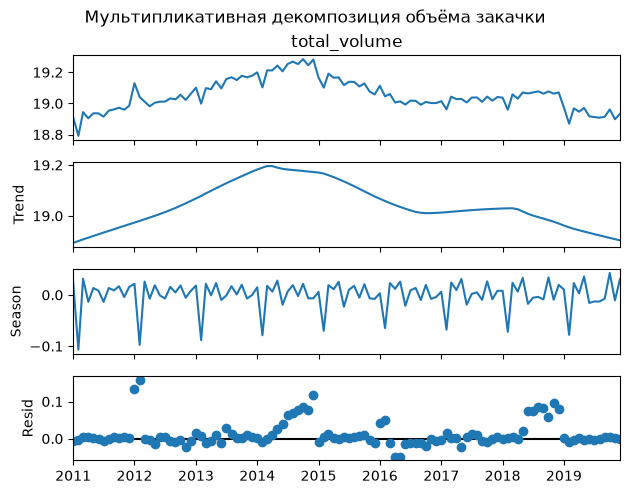

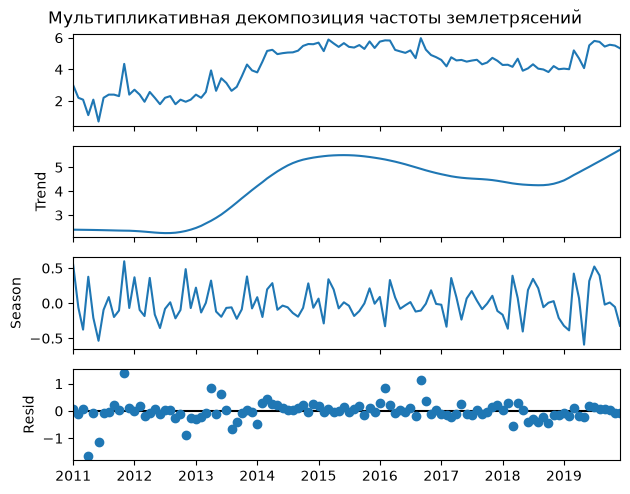

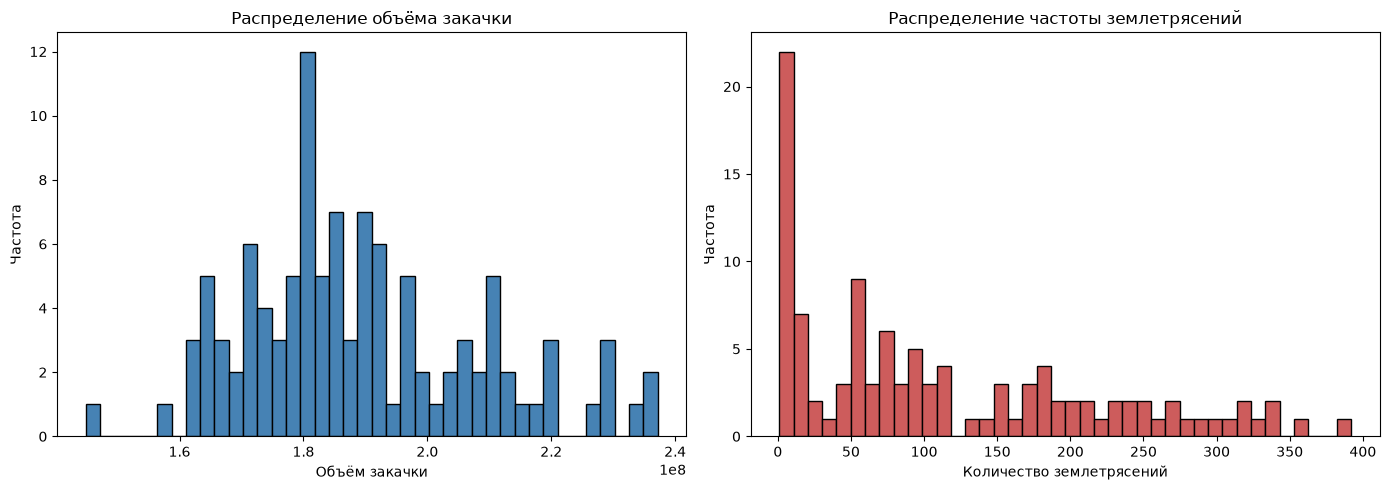

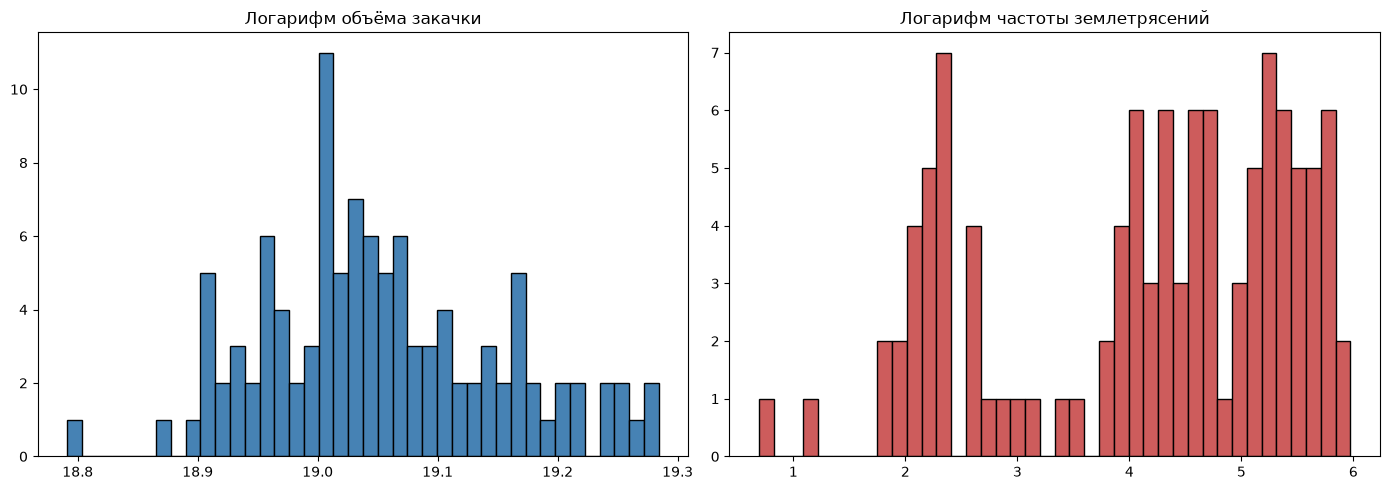

In [39]:
# 3. Аддитивная и мультипликативная сезонность

# -------------------------------
# 1. Временной ряд закачки
# -------------------------------

injection_series = (
    monthly['total_volume']
    .sort_index()
    .asfreq('MS')
    .interpolate()
)

print('Ряд объёма закачки:')
print(injection_series.head())
print(
    f'Период: {injection_series.index.min().date()} — '
    f'{injection_series.index.max().date()}'
)


# -------------------------------
# 2. Временной ряд землетрясений
# -------------------------------

earthquake_series = (
    monthly_earthquakes_common
    .reindex(injection_series.index, fill_value=0)
    .astype(float)
)

print('Ряд частоты землетрясений:')
print(earthquake_series.head())


# -------------------------------
# 3. Аддитивная декомпозиция закачки
# -------------------------------

injection_additive = STL(
    injection_series,
    period=12,
    robust=True
).fit()

injection_additive.plot()
plt.suptitle(
    'Аддитивная декомпозиция объёма закачки',
    y=1.02
)
plt.show()


# -------------------------------
# 4. Аддитивная декомпозиция землетрясений
# -------------------------------

earthquake_additive = STL(
    earthquake_series,
    period=12,
    robust=True
).fit()

earthquake_additive.plot()
plt.suptitle(
    'Аддитивная декомпозиция частоты землетрясений',
    y=1.02
)
plt.show()


# -------------------------------
# 5. Мультипликативная декомпозиция закачки
# -------------------------------

log_injection = np.log1p(injection_series)

injection_multiplicative = STL(
    log_injection,
    period=12,
    robust=True
).fit()

injection_multiplicative.plot()
plt.suptitle(
    'Мультипликативная декомпозиция объёма закачки',
    y=1.02
)
plt.show()


# -------------------------------
# 6. Мультипликативная декомпозиция землетрясений
# -------------------------------

log_earthquakes = np.log1p(earthquake_series)

earthquake_multiplicative = STL(
    log_earthquakes,
    period=12,
    robust=True
).fit()

earthquake_multiplicative.plot()
plt.suptitle(
    'Мультипликативная декомпозиция частоты землетрясений',
    y=1.02
)
plt.show()


# -------------------------------
# 7. Сравнение исходных распределений
# -------------------------------

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(
    injection_series,
    bins=40,
    color='steelblue',
    edgecolor='black'
)
plt.title('Распределение объёма закачки')
plt.xlabel('Объём закачки')
plt.ylabel('Частота')

plt.subplot(1, 2, 2)
plt.hist(
    earthquake_series,
    bins=40,
    color='indianred',
    edgecolor='black'
)
plt.title('Распределение частоты землетрясений')
plt.xlabel('Количество землетрясений')
plt.ylabel('Частота')

plt.tight_layout()
plt.show()


# -------------------------------
# 8. Распределения после логарифмирования
# -------------------------------

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(
    log_injection,
    bins=40,
    color='steelblue',
    edgecolor='black'
)
plt.title('Логарифм объёма закачки')

plt.subplot(1, 2, 2)
plt.hist(
    log_earthquakes,
    bins=40,
    color='indianred',
    edgecolor='black'
)
plt.title('Логарифм частоты землетрясений')

plt.tight_layout()
plt.show()

Годовая статистика объёма закачки:
              mean           std  median    min        max
Year                                                      
2011  16047.945153  49650.317428  3516.5 -434.0  1781945.0
2012  16920.819259  56901.880487  3306.0    0.0  2528313.0
2013  18416.350825  57644.110659  3660.0    0.0  2042348.0
2014  19936.457877  63348.712609  3800.0    0.0  2089704.0
2015  18617.997619  58382.249532  3548.0    0.0  1986359.0
2016  16458.507528  45315.948932  2848.5    0.0  1370947.0
2017  16192.417406  43099.661186  2615.0    0.0  1057307.0
2018  16821.262273  65623.200948  2504.0 -500.0  4013325.0
2019  14703.333629  42346.604193  1769.0    0.0  3660088.0

Годовая статистика землетрясений:
      frequency  mean_magnitude  min_magnitude  max_magnitude
Year                                                         
2011        167        2.886228           1.40            5.7
2012         97        2.816495           1.80            4.1
2013        332        2.757229  

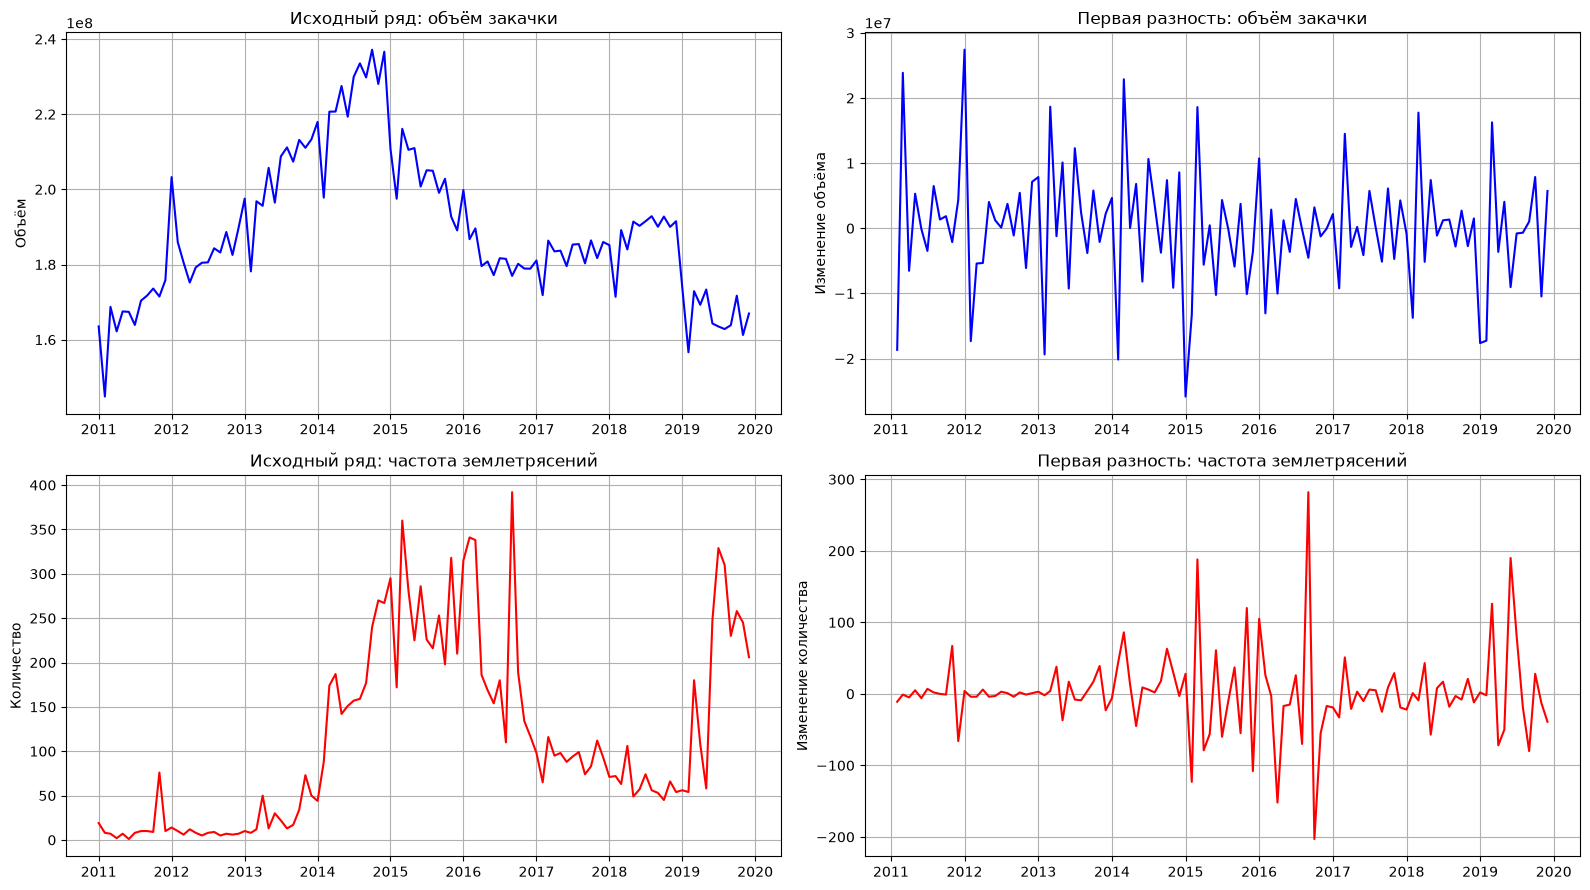

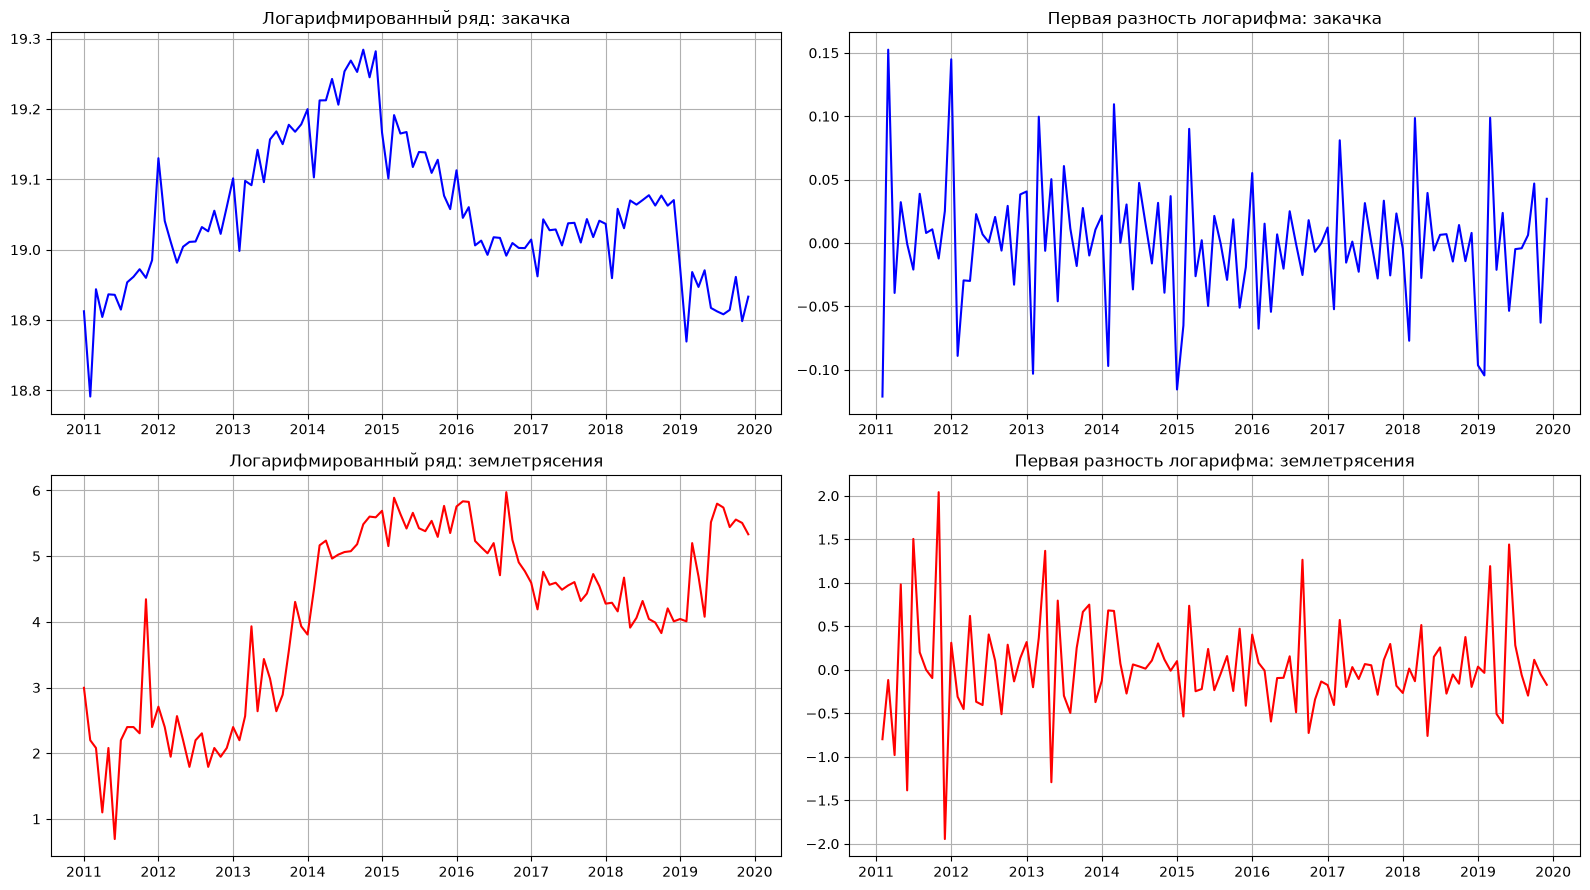

In [40]:
# 4. Стационарность

# -------------------------------
# 1. Годовая статистика закачки
# -------------------------------

injection_year_statistics = (
    volume_long
    .groupby('Year')['volume']
    .agg(
        mean='mean',
        std='std',
        median='median',
        min='min',
        max='max'
    )
)

print('Годовая статистика объёма закачки:')
print(injection_year_statistics)


# -------------------------------
# 2. Годовая статистика землетрясений
# -------------------------------

earthquake_year_statistics = (
    earthquakes_common
    .groupby('Year')['mag']
    .agg(
        frequency='count',
        mean_magnitude='mean',
        min_magnitude='min',
        max_magnitude='max'
    )
)

print('\nГодовая статистика землетрясений:')
print(earthquake_year_statistics)


# -------------------------------
# 3. Первые разности
# -------------------------------

injection_diff = (
    injection_series
    .diff()
    .dropna()
)

earthquake_diff = (
    earthquake_series
    .diff()
    .dropna()
)


# -------------------------------
# 4. Исходные ряды и первые разности
# -------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 9),
    sharex=False
)

axes[0, 0].plot(
    injection_series.index,
    injection_series,
    color='blue'
)
axes[0, 0].set_title(
    'Исходный ряд: объём закачки'
)
axes[0, 0].set_ylabel('Объём')
axes[0, 0].grid(True)

axes[0, 1].plot(
    injection_diff.index,
    injection_diff,
    color='blue'
)
axes[0, 1].set_title(
    'Первая разность: объём закачки'
)
axes[0, 1].set_ylabel('Изменение объёма')
axes[0, 1].grid(True)

axes[1, 0].plot(
    earthquake_series.index,
    earthquake_series,
    color='red'
)
axes[1, 0].set_title(
    'Исходный ряд: частота землетрясений'
)
axes[1, 0].set_ylabel('Количество')
axes[1, 0].grid(True)

axes[1, 1].plot(
    earthquake_diff.index,
    earthquake_diff,
    color='red'
)
axes[1, 1].set_title(
    'Первая разность: частота землетрясений'
)
axes[1, 1].set_ylabel('Изменение количества')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()


# -------------------------------
# 5. Логарифмированные ряды
# -------------------------------

log_injection_diff = (
    log_injection
    .diff()
    .dropna()
)

log_earthquake_diff = (
    log_earthquakes
    .diff()
    .dropna()
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 9),
    sharex=False
)

axes[0, 0].plot(
    log_injection.index,
    log_injection,
    color='blue'
)
axes[0, 0].set_title(
    'Логарифмированный ряд: закачка'
)
axes[0, 0].grid(True)

axes[0, 1].plot(
    log_injection_diff.index,
    log_injection_diff,
    color='blue'
)
axes[0, 1].set_title(
    'Первая разность логарифма: закачка'
)
axes[0, 1].grid(True)

axes[1, 0].plot(
    log_earthquakes.index,
    log_earthquakes,
    color='red'
)
axes[1, 0].set_title(
    'Логарифмированный ряд: землетрясения'
)
axes[1, 0].grid(True)

axes[1, 1].plot(
    log_earthquake_diff.index,
    log_earthquake_diff,
    color='red'
)
axes[1, 1].set_title(
    'Первая разность логарифма: землетрясения'
)
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

In [41]:
# 5. Тесты стационарности ADF и KPSS

def stationarity_tests(data, name):
    data = data.dropna()

    adf_result = adfuller(
        data,
        autolag='AIC'
    )

    kpss_result = kpss(
        data,
        regression='c',
        nlags='auto'
    )

    print(f'\n{name}')
    print('-' * 60)

    print(
        f'ADF statistic: '
        f'{adf_result[0]:.4f}'
    )
    print(
        f'ADF p-value: '
        f'{adf_result[1]:.4f}'
    )

    print(
        f'KPSS statistic: '
        f'{kpss_result[0]:.4f}'
    )
    print(
        f'KPSS p-value: '
        f'{kpss_result[1]:.4f}'
    )

    print('\nВывод:')

    if adf_result[1] < 0.05:
        print(
            'ADF: есть основания считать ряд стационарным'
        )
    else:
        print(
            'ADF: нет оснований считать ряд стационарным'
        )

    if kpss_result[1] > 0.05:
        print(
            'KPSS: нет оснований отвергать стационарность'
        )
    else:
        print(
            'KPSS: ряд, вероятно, нестационарен'
        )


# --------------------------------
# 1. Исходные ряды
# --------------------------------

stationarity_tests(
    injection_series,
    'Исходный ряд: объём закачки'
)

stationarity_tests(
    earthquake_series,
    'Исходный ряд: частота землетрясений'
)


# --------------------------------
# 2. Первые разности
# --------------------------------

stationarity_tests(
    injection_diff,
    'Первая разность: объём закачки'
)

stationarity_tests(
    earthquake_diff,
    'Первая разность: частота землетрясений'
)


# --------------------------------
# 3. Логарифмированные ряды
# --------------------------------

stationarity_tests(
    log_injection,
    'Логарифмированный ряд: объём закачки'
)

stationarity_tests(
    log_earthquakes,
    'Логарифмированный ряд: частота землетрясений'
)


# --------------------------------
# 4. Первые разности логарифмов
# --------------------------------

stationarity_tests(
    log_injection_diff,
    'Первая разность логарифма: объём закачки'
)

stationarity_tests(
    log_earthquake_diff,
    'Первая разность логарифма: частота землетрясений'
)


Исходный ряд: объём закачки
------------------------------------------------------------
ADF statistic: -1.1313
ADF p-value: 0.7024
KPSS statistic: 0.4012
KPSS p-value: 0.0766

Вывод:
ADF: нет оснований считать ряд стационарным
KPSS: нет оснований отвергать стационарность

Исходный ряд: частота землетрясений
------------------------------------------------------------
ADF statistic: -1.6727
ADF p-value: 0.4452
KPSS statistic: 0.6153
KPSS p-value: 0.0212

Вывод:
ADF: нет оснований считать ряд стационарным
KPSS: ряд, вероятно, нестационарен

Первая разность: объём закачки
------------------------------------------------------------
ADF statistic: -2.6532
ADF p-value: 0.0825
KPSS statistic: 0.2775
KPSS p-value: 0.1000

Вывод:
ADF: нет оснований считать ряд стационарным
KPSS: нет оснований отвергать стационарность

Первая разность: частота землетрясений
------------------------------------------------------------
ADF statistic: -2.9664
ADF p-value: 0.0382
KPSS statistic: 0.0840
KPSS p-val

C:\Users\Денис\AppData\Local\Temp\ipykernel_24008\1000599866.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
C:\Users\Денис\AppData\Local\Temp\ipykernel_24008\1000599866.py:11: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(
C:\Users\Денис\AppData\Local\Temp\ipykernel_24008\1000599866.py:6

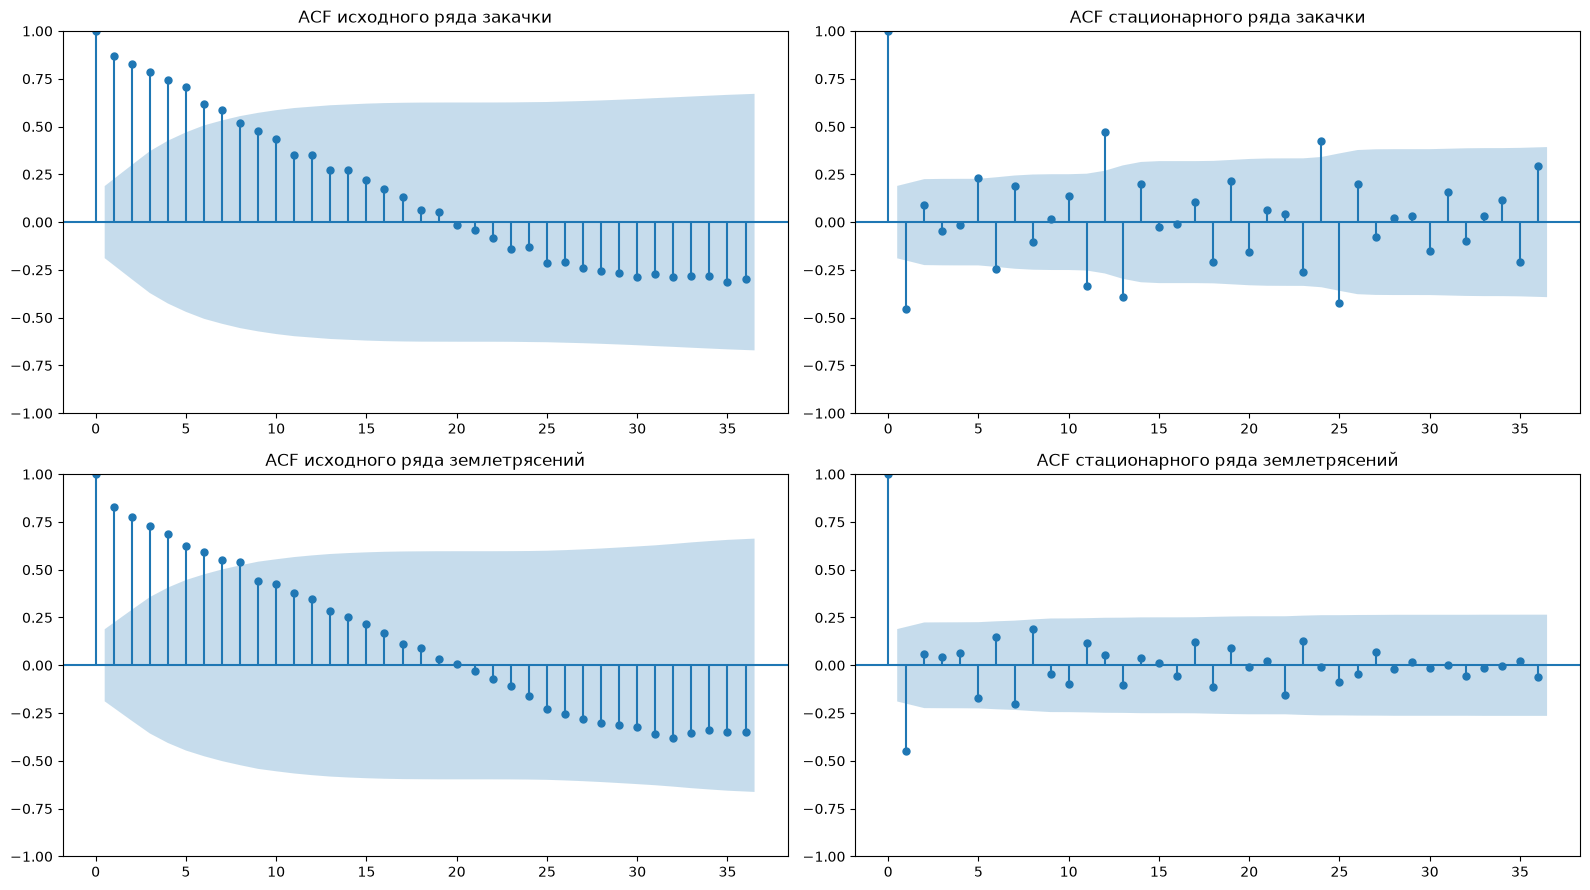

Автокорреляция объёма закачки:
Лаг 1: 0.8813
Лаг 2: 0.8688
Лаг 3: 0.8324
Лаг 6: 0.6875
Лаг 12: 0.4100
Лаг 24: -0.2021
Лаг 36: -0.4311

Автокорреляция частоты землетрясений:
Лаг 1: 0.8340
Лаг 2: 0.7929
Лаг 3: 0.7583
Лаг 6: 0.6616
Лаг 12: 0.4124
Лаг 24: -0.2004
Лаг 36: -0.5324


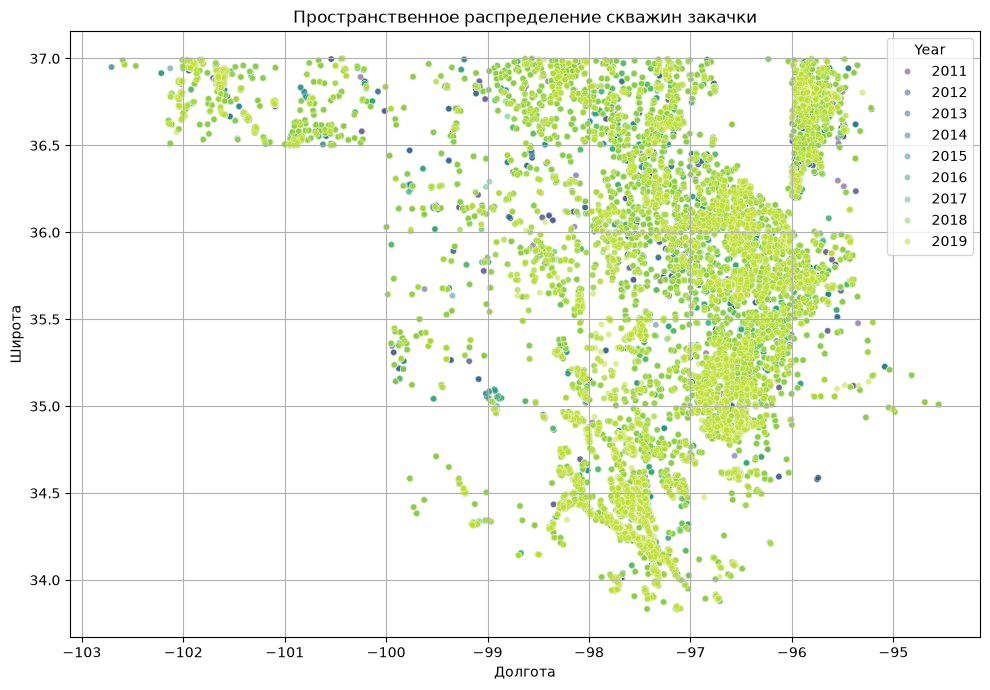

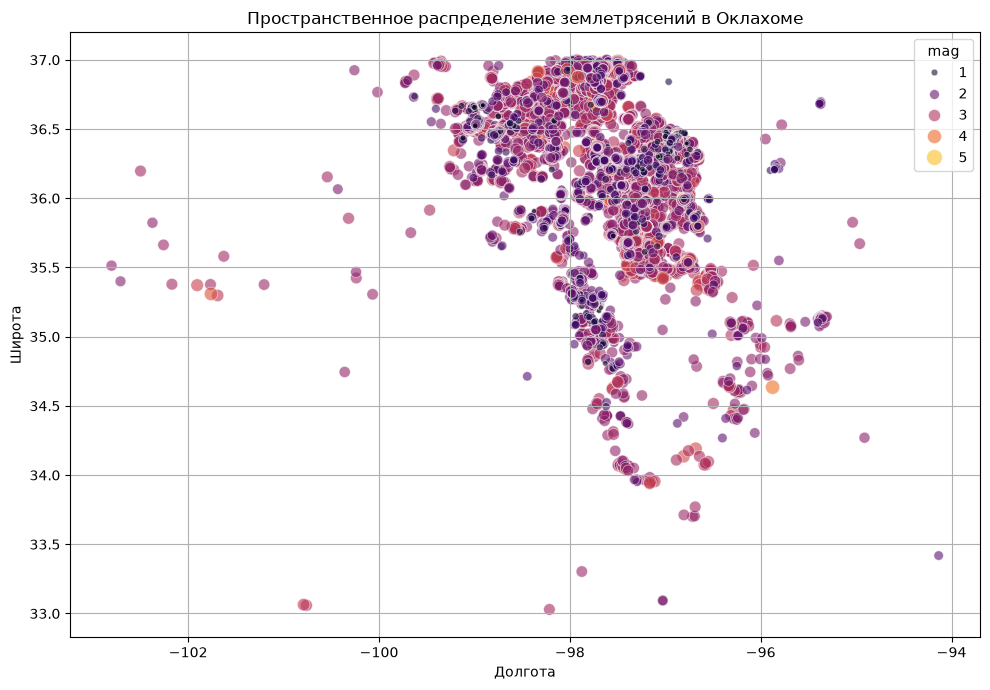

Статистика закачки по округам:
              wells  total_injection  average_latitude  average_longitude
County                                                                   
CARTER         1955     3.342019e+09         34.316754         -97.463531
ALFALFA         142     1.656246e+09         36.820158         -98.311917
CREEK          1085     1.490993e+09         35.923739         -96.368423
STEPHENS       1477     1.450592e+09         34.419859         -97.686824
PONTOTOC        767     1.400413e+09         34.731804         -96.588213
SEMINOLE        566     1.161875e+09         35.135301         -96.613974
WOODS           125     8.359344e+08         36.779540         -98.751646
TEXAS           420     6.073421e+08         36.839536        -101.630358
KAY             260     5.567553e+08         36.782655         -97.186855
POTTAWATOMIE    292     5.081544e+08         35.149611         -96.901093


In [42]:
# 6. Автокорреляция и пространственный анализ


# -------------------------------
# 1. ACF исходных рядов
# -------------------------------

max_lags = min(36, len(injection_series) // 2)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 9)
)

plot_acf(
    injection_series.dropna(),
    lags=max_lags,
    ax=axes[0, 0]
)
axes[0, 0].set_title(
    'ACF исходного ряда закачки'
)

plot_acf(
    log_injection_diff.dropna(),
    lags=max_lags,
    ax=axes[0, 1]
)
axes[0, 1].set_title(
    'ACF стационарного ряда закачки'
)

plot_acf(
    earthquake_series.dropna(),
    lags=max_lags,
    ax=axes[1, 0]
)
axes[1, 0].set_title(
    'ACF исходного ряда землетрясений'
)

plot_acf(
    log_earthquake_diff.dropna(),
    lags=max_lags,
    ax=axes[1, 1]
)
axes[1, 1].set_title(
    'ACF стационарного ряда землетрясений'
)

plt.tight_layout()
plt.show()


# -------------------------------
# 2. Численные значения
# -------------------------------

lags_to_check = [1, 2, 3, 6, 12, 24, 36]

print('Автокорреляция объёма закачки:')

for lag in lags_to_check:
    if lag < len(injection_series):
        print(
            f'Лаг {lag}: '
            f'{injection_series.autocorr(lag=lag):.4f}'
        )


print('\nАвтокорреляция частоты землетрясений:')

for lag in lags_to_check:
    if lag < len(earthquake_series):
        print(
            f'Лаг {lag}: '
            f'{earthquake_series.autocorr(lag=lag):.4f}'
        )


# -------------------------------
# 3. Данные для пространственного анализа
# -------------------------------

spatial_injection = df.dropna(
    subset=['LAT', 'LON', 'Year', 'API']
).copy()

spatial_injection = spatial_injection[
    spatial_injection['LAT'].between(33, 37) &
    spatial_injection['LON'].between(-103, -94) &
    spatial_injection['Year'].between(2011, 2019)
]

spatial_injection['Year'] = (
    spatial_injection['Year'].astype(str)
)


earthquakes_common['Year'] = (
    earthquakes_common['date'].dt.year.astype(str)
)


# -------------------------------
# 4. Скважины закачки
# -------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=spatial_injection,
    x='LON',
    y='LAT',
    hue='Year',
    palette='viridis',
    alpha=0.5,
    s=20
)

plt.title(
    'Пространственное распределение '
    'скважин закачки'
)
plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 5. Землетрясения
# -------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=earthquakes_common,
    x='longitude',
    y='latitude',
    hue='mag',
    size='mag',
    palette='inferno',
    sizes=(10, 150),
    alpha=0.6
)

plt.title(
    'Пространственное распределение '
    'землетрясений в Оклахоме'
)
plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 6. Статистика по округам
# -------------------------------
well_metadata = (
    df[
        ['API', 'County', 'LAT', 'LON']
    ]
    .drop_duplicates('API')
)

volume_for_counties = volume_long.merge(
    well_metadata,
    on='API',
    how='left'
)

county_statistics = (
    volume_for_counties[
        volume_for_counties['Year'].between(2011, 2019)
    ]
    .dropna(
        subset=[
            'County',
            'API',
            'volume',
            'LAT',
            'LON'
        ]
    )
    .groupby('County')
    .agg(
        wells=('API', 'nunique'),
        total_injection=('volume', 'sum'),
        average_latitude=('LAT', 'mean'),
        average_longitude=('LON', 'mean')
    )
    .sort_values(
        'total_injection',
        ascending=False
    )
)

print('Статистика закачки по округам:')
print(county_statistics.head(10))

CCF: закачка и частота землетрясений
    lag       ccf
0   -12 -0.004365
1   -11  0.060885
2   -10  0.173007
3    -9 -0.347582
4    -8  0.300817
5    -7 -0.112530
6    -6  0.172103
7    -5 -0.213488
8    -4  0.040604
9    -3  0.181422
10   -2 -0.112325
11   -1 -0.048380
12    0  0.058852
13    1 -0.050315
14    2  0.180567
15    3 -0.179083
16    4  0.111413
17    5 -0.078555
18    6  0.174917
19    7 -0.163306
20    8  0.013774
21    9  0.096554
22   10 -0.174879
23   11  0.008913
24   12  0.012936

Максимальная связь с частотой: лаг -9; CCF = -0.3476

CCF: закачка и максимальная магнитуда
    lag       ccf
0   -12 -0.124747
1   -11  0.113470
2   -10  0.006131
3    -9 -0.222310
4    -8  0.219336
5    -7 -0.085983
6    -6  0.102640
7    -5 -0.105195
8    -4  0.026270
9    -3  0.033332
10   -2 -0.016704
11   -1  0.017723
12    0 -0.032276
13    1 -0.057516
14    2  0.134563
15    3 -0.011752
16    4  0.041951
17    5 -0.071176
18    6  0.075396
19    7 -0.123065
20    8  0.067502
21    

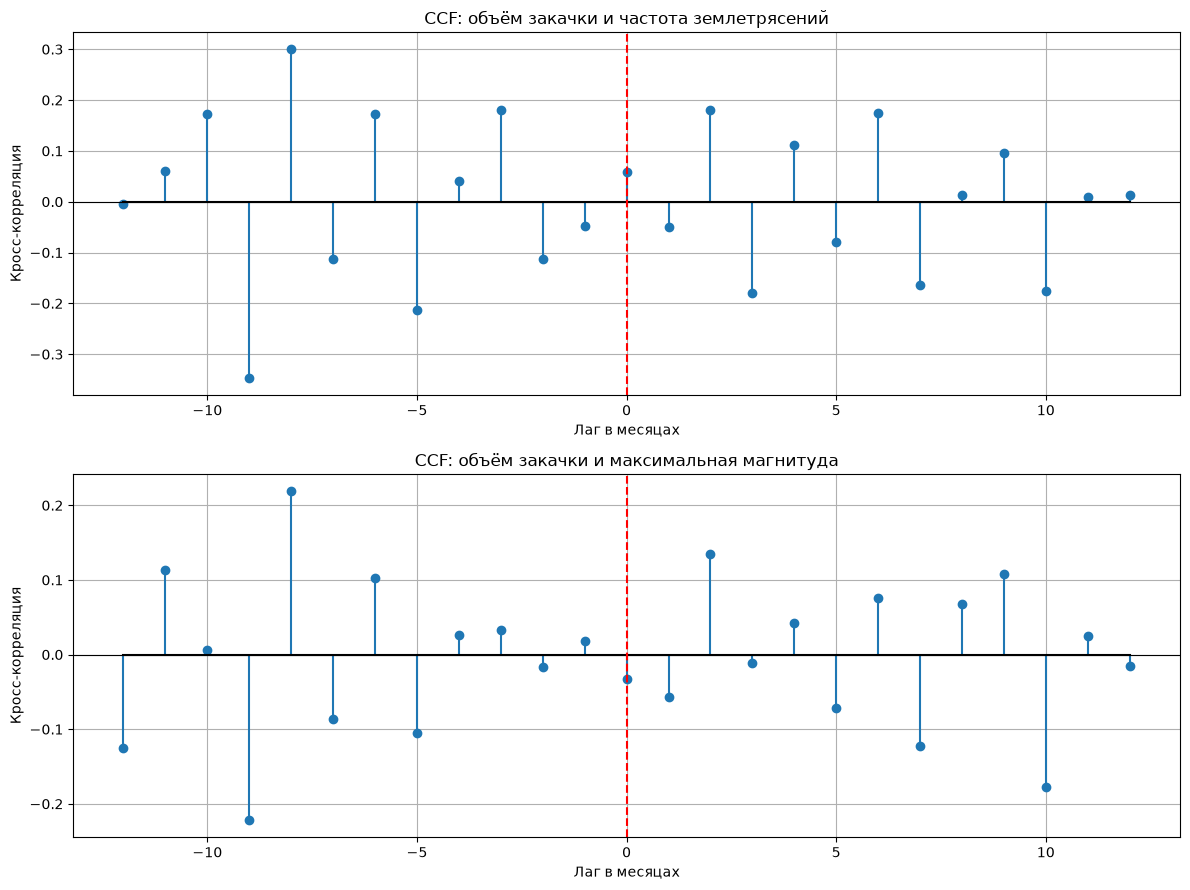

In [43]:
# 7. Кросс-корреляция (CCF)

# -------------------------------
# 1. Месячные показатели землетрясений
# -------------------------------

monthly_earthquake_features = (
    earthquakes_common
    .groupby('date')
    .agg(
        frequency=('mag', 'count'),
        max_magnitude=('mag', 'max')
    )
    .reindex(injection_series.index)
)

monthly_earthquake_features['frequency'] = (
    monthly_earthquake_features['frequency']
    .fillna(0)
)

monthly_earthquake_features['max_magnitude'] = (
    monthly_earthquake_features['max_magnitude']
    .fillna(0)
)


# -------------------------------
# 2. Стационарные ряды
# -------------------------------

ccf_injection = log_injection_diff.copy()

ccf_frequency = (
    np.log1p(
        monthly_earthquake_features['frequency']
    )
    .diff()
    .dropna()
)

ccf_magnitude = (
    np.log1p(
        monthly_earthquake_features['max_magnitude']
    )
    .diff()
    .dropna()
)


# -------------------------------
# 3. Функция расчёта CCF
# -------------------------------

def calculate_ccf(x, y, max_lag=12):
    data = pd.concat(
        [x.rename('x'), y.rename('y')],
        axis=1
    ).dropna()

    x = data['x'].to_numpy()
    y = data['y'].to_numpy()

    max_lag = min(
        max_lag,
        len(data) // 3
    )

    results = []

    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            x_part = x[:lag]
            y_part = y[-lag:]
        elif lag > 0:
            x_part = x[lag:]
            y_part = y[:-lag]
        else:
            x_part = x
            y_part = y

        correlation = np.corrcoef(
            x_part,
            y_part
        )[0, 1]

        results.append({
            'lag': lag,
            'ccf': correlation
        })

    return pd.DataFrame(results)


# -------------------------------
# 4. CCF закачки и частоты
# -------------------------------

ccf_frequency = calculate_ccf(
    ccf_injection,
    ccf_frequency,
    max_lag=12
)

print('CCF: закачка и частота землетрясений')
print(ccf_frequency)

max_frequency_row = ccf_frequency.loc[
    ccf_frequency['ccf'].abs().idxmax()
]

print(
    f'\nМаксимальная связь с частотой: '
    f'лаг {int(max_frequency_row["lag"])}; '
    f'CCF = {max_frequency_row["ccf"]:.4f}'
)


# -------------------------------
# 5. CCF закачки и магнитуды
# -------------------------------

ccf_magnitude_result = calculate_ccf(
    ccf_injection,
    ccf_magnitude,
    max_lag=12
)

print('\nCCF: закачка и максимальная магнитуда')
print(ccf_magnitude_result)

max_magnitude_row = ccf_magnitude_result.loc[
    ccf_magnitude_result['ccf'].abs().idxmax()
]

print(
    f'\nМаксимальная связь с магнитудой: '
    f'лаг {int(max_magnitude_row["lag"])}; '
    f'CCF = {max_magnitude_row["ccf"]:.4f}'
)


# -------------------------------
# 6. Графики CCF
# -------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9)
)

axes[0].stem(
    ccf_frequency['lag'],
    ccf_frequency['ccf'],
    basefmt='k-'
)

axes[0].axhline(
    0,
    color='black',
    linewidth=0.8
)

axes[0].axvline(
    0,
    color='red',
    linestyle='--'
)

axes[0].set_title(
    'CCF: объём закачки и частота землетрясений'
)
axes[0].set_xlabel('Лаг в месяцах')
axes[0].set_ylabel('Кросс-корреляция')
axes[0].grid(True)


axes[1].stem(
    ccf_magnitude_result['lag'],
    ccf_magnitude_result['ccf'],
    basefmt='k-'
)

axes[1].axhline(
    0,
    color='black',
    linewidth=0.8
)

axes[1].axvline(
    0,
    color='red',
    linestyle='--'
)

axes[1].set_title(
    'CCF: объём закачки и максимальная магнитуда'
)
axes[1].set_xlabel('Лаг в месяцах')
axes[1].set_ylabel('Кросс-корреляция')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [44]:
# 8. Пространственно-временная подготовка данных
#    для CNN-LSTM, Conv3D и GConvGRU

# Размер пространственной сетки
GRID_ROWS = 20
GRID_COLS = 20


# -------------------------------
# 1. Координаты скважин
# -------------------------------

well_metadata = (
    df[
        ['API', 'LAT', 'LON']
    ]
    .drop_duplicates('API')
)

injection_points = volume_long.merge(
    well_metadata,
    on='API',
    how='left'
)

injection_points['date'] = pd.to_datetime(
    injection_points['date']
)


# -------------------------------
# 2. Общие границы территории
# -------------------------------

lat_min = min(
    injection_points['LAT'].min(),
    earthquakes_common['latitude'].min()
)

lat_max = max(
    injection_points['LAT'].max(),
    earthquakes_common['latitude'].max()
)

lon_min = min(
    injection_points['LON'].min(),
    earthquakes_common['longitude'].min()
)

lon_max = max(
    injection_points['LON'].max(),
    earthquakes_common['longitude'].max()
)

lat_edges = np.linspace(
    lat_min,
    lat_max,
    GRID_ROWS + 1
)

lon_edges = np.linspace(
    lon_min,
    lon_max,
    GRID_COLS + 1
)


# -------------------------------
# 3. Присвоение ячеек сетки
# -------------------------------

injection_points['lat_cell'] = pd.cut(
    injection_points['LAT'],
    bins=lat_edges,
    labels=False,
    include_lowest=True
)

injection_points['lon_cell'] = pd.cut(
    injection_points['LON'],
    bins=lon_edges,
    labels=False,
    include_lowest=True
)

earthquake_points = earthquakes_common.copy()

earthquake_points['lat_cell'] = pd.cut(
    earthquake_points['latitude'],
    bins=lat_edges,
    labels=False,
    include_lowest=True
)

earthquake_points['lon_cell'] = pd.cut(
    earthquake_points['longitude'],
    bins=lon_edges,
    labels=False,
    include_lowest=True
)


# -------------------------------
# 4. Агрегация закачки по месяцам
# -------------------------------

injection_grid = (
    injection_points
    .groupby(
        [
            'date',
            'lat_cell',
            'lon_cell'
        ],
        observed=True
    )
    .agg(
        injection_volume=('volume', 'sum')
    )
    .reset_index()
)


# -------------------------------
# 5. Агрегация землетрясений
# -------------------------------

earthquake_grid = (
    earthquake_points
    .groupby(
        [
            'date',
            'lat_cell',
            'lon_cell'
        ],
        observed=True
    )
    .agg(
        earthquake_count=('mag', 'count'),
        max_magnitude=('mag', 'max')
    )
    .reset_index()
)


# -------------------------------
# 6. Объединённая пространственная таблица
# -------------------------------

spatial_monthly = pd.merge(
    injection_grid,
    earthquake_grid,
    on=[
        'date',
        'lat_cell',
        'lon_cell'
    ],
    how='outer'
)

spatial_monthly[
    [
        'injection_volume',
        'earthquake_count',
        'max_magnitude'
    ]
] = spatial_monthly[
    [
        'injection_volume',
        'earthquake_count',
        'max_magnitude'
    ]
].fillna(0)

spatial_monthly = spatial_monthly.sort_values(
    [
        'date',
        'lat_cell',
        'lon_cell'
    ]
)

print('Размер пространственно-временной таблицы:')
print(spatial_monthly.shape)

print('\nПервые строки:')
print(spatial_monthly.head(10))


print(
    spatial_monthly[
        spatial_monthly['earthquake_count'] > 0
    ].head()
)

print(
    spatial_monthly['earthquake_count'].sum()
)

print(
    spatial_monthly['max_magnitude'].max()
)

Размер пространственно-временной таблицы:
(19145, 6)

Первые строки:
        date  lat_cell  lon_cell  injection_volume  earthquake_count  \
0 2011-01-01         4        11      1.748450e+05               0.0   
1 2011-01-01         4        12      6.662533e+04               0.0   
2 2011-01-01         4        13      5.903100e+04               0.0   
3 2011-01-01         4        14      2.114500e+04               0.0   
4 2011-01-01         5         9      2.120400e+04               0.0   
5 2011-01-01         5        10      5.500000e+03               0.0   
6 2011-01-01         5        11      1.669500e+04               0.0   
7 2011-01-01         5        12      6.678961e+06               0.0   
8 2011-01-01         5        13      6.606700e+04               0.0   
9 2011-01-01         5        14      5.220308e+04               0.0   

   max_magnitude  
0            0.0  
1            0.0  
2            0.0  
3            0.0  
4            0.0  
5            0.0  
6    

In [45]:
# 9. Глобальная пространственная автокорреляция
#    Индекс Moran's I


# -------------------------------
# 1. Агрегация показателей по ячейкам
# -------------------------------

spatial_cells = (
    spatial_monthly
    .groupby(
        ['lat_cell', 'lon_cell'],
        as_index=False
    )
    .agg(
        total_injection=(
            'injection_volume',
            'sum'
        ),
        total_earthquakes=(
            'earthquake_count',
            'sum'
        ),
        maximum_magnitude=(
            'max_magnitude',
            'max'
        )
    )
)


# -------------------------------
# 2. Пространственные координаты
# -------------------------------

coordinates = spatial_cells[
    ['lat_cell', 'lon_cell']
].to_numpy()

number_of_neighbors = min(
    4,
    len(spatial_cells) - 1
)

weights = KNN.from_array(
    coordinates,
    k=number_of_neighbors
)

weights.transform = 'R'


# -------------------------------
# 3. Расчёт Moran's I
# -------------------------------

variables = [
    'total_injection',
    'total_earthquakes',
    'maximum_magnitude'
]

for variable in variables:
    values = spatial_cells[variable].to_numpy()

    if np.std(values) == 0:
        print(
            f'{variable}: невозможно рассчитать — '
            f'все значения одинаковые'
        )
        continue

    moran = Moran(
        values,
        weights,
        permutations=999
    )

    print(f'\nПоказатель: {variable}')
    print(f"Moran's I: {moran.I:.4f}")
    print(f'p-value: {moran.p_sim:.4f}')
    print(f'z-score: {moran.z_sim:.4f}')

    if moran.p_sim < 0.05:
        if moran.I > 0:
            print(
                'Вывод: статистически значимая '
                'положительная пространственная автокорреляция.'
            )
        else:
            print(
                'Вывод: статистически значимая '
                'отрицательная пространственная автокорреляция.'
            )
    else:
        print(
            'Вывод: статистически значимая '
            'пространственная автокорреляция не обнаружена.'
        )


Показатель: total_injection
Moran's I: 0.4001
p-value: 0.0010
z-score: 9.4360
Вывод: статистически значимая положительная пространственная автокорреляция.

Показатель: total_earthquakes
Moran's I: 0.4986
p-value: 0.0010
z-score: 11.4396
Вывод: статистически значимая положительная пространственная автокорреляция.

Показатель: maximum_magnitude
Moran's I: 0.5800
p-value: 0.0010
z-score: 12.8518
Вывод: статистически значимая положительная пространственная автокорреляция.



Локальные кластеры: total_injection
total_injection_cluster
Не значимо    152
LL             39
HH             14
LH              2
Name: count, dtype: int64

Локальные кластеры: total_earthquakes
total_earthquakes_cluster
Не значимо    147
LL             38
HH             20
LH              2
Name: count, dtype: int64

Локальные кластеры: maximum_magnitude
maximum_magnitude_cluster
Не значимо    120
LL             41
HH             40
HL              6
Name: count, dtype: int64


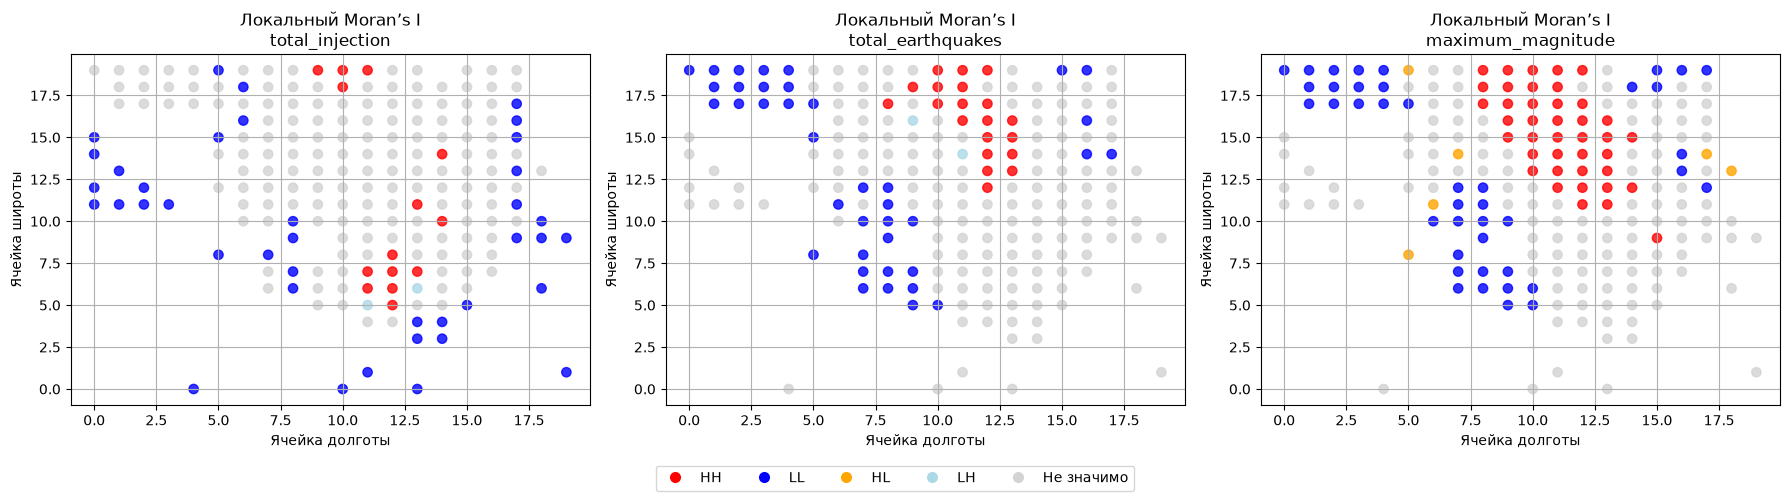

In [46]:
# -------------------------------
# 10. Локальный Moran's I
# -------------------------------

cluster_labels = {
    1: 'HH',
    2: 'LH',
    3: 'LL',
    4: 'HL'
}

cluster_colors = {
    'HH': 'red',
    'LL': 'blue',
    'HL': 'orange',
    'LH': 'lightblue',
    'Не значимо': 'lightgray'
}


local_results = {}

for variable in variables:
    values = spatial_cells[variable].to_numpy()

    if np.std(values) == 0:
        print(
            f'\n{variable}: локальный Moran невозможен — '
            f'все значения одинаковые'
        )
        continue

    local_moran = Moran_Local(
        values,
        weights,
        permutations=999
    )

    spatial_cells[f'{variable}_local_I'] = (
        local_moran.Is
    )

    spatial_cells[f'{variable}_p_value'] = (
        local_moran.p_sim
    )

    spatial_cells[f'{variable}_cluster'] = [
        cluster_labels[q]
        if p < 0.05
        else 'Не значимо'
        for q, p in zip(
            local_moran.q,
            local_moran.p_sim
        )
    ]

    local_results[variable] = local_moran

    print(f'\nЛокальные кластеры: {variable}')
    print(
        spatial_cells[
            f'{variable}_cluster'
        ].value_counts()
    )


# -------------------------------
# 5. Карты локальных кластеров
# -------------------------------

fig, axes = plt.subplots(
    1,
    len(local_results),
    figsize=(18, 5)
)

if len(local_results) == 1:
    axes = [axes]

for ax, variable in zip(
    axes,
    local_results.keys()
):
    colors = spatial_cells[
        f'{variable}_cluster'
    ].map(cluster_colors)

    ax.scatter(
        spatial_cells['lon_cell'],
        spatial_cells['lat_cell'],
        c=colors,
        s=45,
        alpha=0.8
    )

    ax.set_title(
        f'Локальный Moran’s I\n{variable}'
    )
    ax.set_xlabel('Ячейка долготы')
    ax.set_ylabel('Ячейка широты')
    ax.grid(True)

legend_handles = [
    plt.Line2D(
        [0],
        [0],
        marker='o',
        color='w',
        label=label,
        markerfacecolor=color,
        markersize=9
    )
    for label, color in cluster_colors.items()
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    ncol=5
)

plt.tight_layout()
plt.subplots_adjust(
    bottom=0.18
)
plt.show()

## 11. Анализ пространственной зависимости: семивариограмма

In [47]:
# Центры пространственных ячеек в километрах.
# Приближение учитывает уменьшение длины градуса долготы с широтой.
semivariogram_data = spatial_cells.copy()
semivariogram_data['lat_center'] = (
    lat_edges[semivariogram_data['lat_cell'].astype(int)]
    + np.diff(lat_edges).mean() / 2
)
semivariogram_data['lon_center'] = (
    lon_edges[semivariogram_data['lon_cell'].astype(int)]
    + np.diff(lon_edges).mean() / 2
)

latitude_scale = 111.32
longitude_scale = (
    111.32
    * np.cos(np.deg2rad(semivariogram_data['lat_center'].mean()))
)

coordinates_km = np.column_stack([
    semivariogram_data['lon_center'].to_numpy() * longitude_scale,
    semivariogram_data['lat_center'].to_numpy() * latitude_scale
])

pair_distances = []
pair_differences = {variable: [] for variable in variables}

for first in range(len(semivariogram_data)):
    for second in range(first + 1, len(semivariogram_data)):
        distance = np.linalg.norm(
            coordinates_km[first] - coordinates_km[second]
        )
        pair_distances.append(distance)

        for variable in variables:
            first_value = semivariogram_data.iloc[first][variable]
            second_value = semivariogram_data.iloc[second][variable]
            pair_differences[variable].append(
                0.5 * (first_value - second_value) ** 2
            )

pair_distances = np.asarray(pair_distances)
number_of_bins = 12
distance_bins = np.linspace(
    0,
    pair_distances.max(),
    number_of_bins + 1
)



total_injection
      lag_km  semivariance  number_of_pairs
0    46.6840  4.669405e+16             1243
1   108.7722  5.095787e+16             3638
2   178.2271  5.224772e+16             4145
3   246.0521  5.934419e+16             4113
4   312.5496  5.466164e+16             3032
5   381.6301  3.295800e+16             2286
6   454.1041  3.891476e+16             1338
7   526.8598  4.233848e+16              804
8   596.5757  1.303357e+16              494
9   660.6997  3.685746e+15              177
10  726.5382  7.715907e+13               41
11  791.5329  1.204358e+16                9

total_earthquakes
      lag_km  semivariance  number_of_pairs
0    46.6840    19124.1685             1243
1   108.7722    27547.0004             3638
2   178.2271    35713.3585             4145
3   246.0521    36596.0080             4113
4   312.5496    26766.0447             3032
5   381.6301    18738.2238             2286
6   454.1041    18533.5818             1338
7   526.8598     5073.7158              

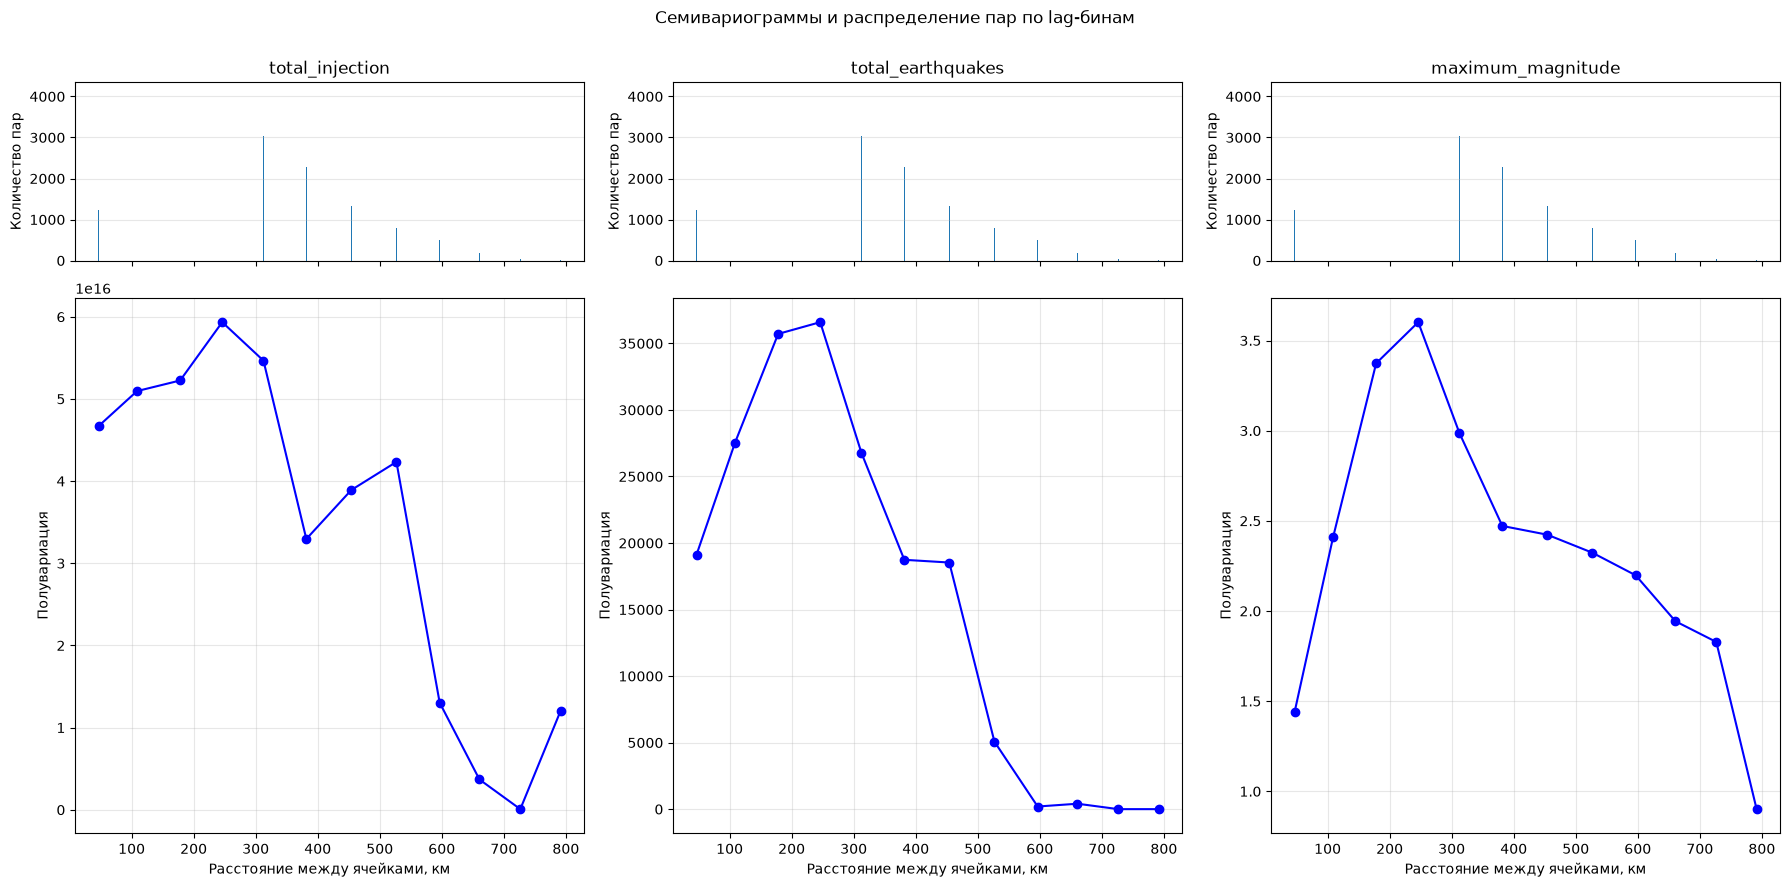

In [48]:
fig, axes = plt.subplots(
    2,
    len(variables),
    figsize=(18, 9),
    sharex='col',
    gridspec_kw={'height_ratios': [1, 3]}
)

for column, variable in enumerate(variables):
    values = np.asarray(pair_differences[variable])
    bin_numbers = np.digitize(pair_distances, distance_bins)
    lag_distances = []
    semivariances = []
    pair_counts = []

    for bin_number in range(1, number_of_bins + 1):
        selected = bin_numbers == bin_number
        if not np.any(selected):
            continue

        lag_distances.append(pair_distances[selected].mean())
        semivariances.append(values[selected].mean())
        pair_counts.append(selected.sum())

    histogram_ax = axes[0, column]
    semivariogram_ax = axes[1, column]
    histogram_ax.bar(lag_distances, pair_counts)
    semivariogram_ax.plot(
        lag_distances,
        semivariances,
        marker='o',
        color='blue'
    )
    histogram_ax.set_title(variable)
    histogram_ax.set_ylabel('Количество пар')
    histogram_ax.grid(axis='y', alpha=0.3)
    semivariogram_ax.scatter(
        lag_distances,
        semivariances,
        color='blue',
        s=25
    )
    semivariogram_ax.set_xlabel('Расстояние между ячейками, км')
    semivariogram_ax.set_ylabel('Полувариация')
    semivariogram_ax.grid(alpha=0.3)

    print(f'\n{variable}')
    print(pd.DataFrame({
        'lag_km': lag_distances,
        'semivariance': semivariances,
        'number_of_pairs': pair_counts
    }).round(4))

fig.suptitle('Семивариограммы и распределение пар по lag-бинам')
plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.show()

1. Implementujte a natrénujte prvý pridelený model na riešenie vhodne zvoleného problému, vyhodnoťte jeho výsledky a vysvetlite, ako model pracuje s priestorovými a časovými vlastnosťami dát, aké sú jeho výhody a obmedzenia.

Conv3D

2. Implementujte a natrénujte druhý pridelený model na riešenie rovnakého problému, porovnajte jeho výsledky s prvým modelom a vysvetlite rozdiely medzi ich architektúrami.

GConvGRU

3. CNN-LSTM - Implementácia, vedieť porovnať architektúru a výsledky s prvými dvoma modelmi

Analyzujte a porovnajte vplyv vtláčania priemyselných odpadových vôd na frekvenciu a intenzitu zemetrasení v priestore a čase v oblasti Oklahomy. Porovnajte presnosť predikcie modelov pri rozličnej intenzite vtláčania na vybraných dátach.
